
# Fake News Detection Using Machine Learning

## 1. Problem Statement
Fake news can mislead readers and spread false information. The objective of this project is to build a Machine Learning model that classifies a news article as Fake or Real based on its textual content.

## 2. Objective
The main objectives of this project are:
- Process and prepare the news article dataset.
- Convert text into numerical features using TF-IDF.
- Train and compare Logistic Regression and Naive Bayes classifiers.
- Evaluate the models using appropriate classification metrics.
- Develop a Streamlit web application to predict whether an article is Fake or Real.

## 3. Dataset Description
We use the Fake and Real News Dataset, which consists of two CSV files:

- **Fake.csv:** Contains 23,502 fake news articles.
- **True.csv:** Contains 21,417 real news articles.

The dataset contains the following columns:

| Column | Description |
|---|---|
| Title | Headline of the news article |
| Text | Main content of the news article |
| Subject | Category or subject of the article |
| Date | Publication date of the article |

The two files will be combined into a single dataset with a target label indicating whether an article is Fake or Real.



In [34]:
# Pandas is used to load, inspect, and combine the CSV datasets.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns


In [35]:
# Load the fake news articles from the Data folder.
fake_df = pd.read_csv("Data/Fake.csv")

# Load the real news articles from the Data folder.
real_df = pd.read_csv("Data/True.csv")

# Display a confirmation that both datasets have been loaded.
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [36]:
real_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [37]:
# Display the number of rows and columns in the fake news dataset.
print("Fake dataset shape:", fake_df.shape)

# Display the number of rows and columns in the real news dataset.
print("Real dataset shape:", real_df.shape)

Fake dataset shape: (23481, 4)
Real dataset shape: (21417, 4)


In [38]:
# Display the column names available in the fake news dataset.
print("Fake dataset columns:", fake_df.columns.tolist())

# Display the column names available in the real news dataset.
print("Real dataset columns:", real_df.columns.tolist())

# Check data types and non-null counts in the fake news dataset.
print("\nFake dataset information:")
fake_df.info()

# Check data types and non-null counts in the real news dataset.
print("\nReal dataset information:")
real_df.info()

Fake dataset columns: ['title', 'text', 'subject', 'date']
Real dataset columns: ['title', 'text', 'subject', 'date']

Fake dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    23481 non-null  str  
 1   text     23481 non-null  str  
 2   subject  23481 non-null  str  
 3   date     23481 non-null  str  
dtypes: str(4)
memory usage: 733.9 KB

Real dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    21417 non-null  str  
 1   text     21417 non-null  str  
 2   subject  21417 non-null  str  
 3   date     21417 non-null  str  
dtypes: str(4)
memory usage: 669.4 KB


In [39]:
# Assign label 0 to fake news articles.
fake_df["label"] = 0

# Assign label 1 to real news articles.
real_df["label"] = 1

# Verify that the labels have been added to both datasets.
print("Fake dataset labels:")
print(fake_df["label"].value_counts())

print("\nReal dataset labels:")
print(real_df["label"].value_counts())

Fake dataset labels:
label
0    23481
Name: count, dtype: int64

Real dataset labels:
label
1    21417
Name: count, dtype: int64


In [40]:
# Combine fake and real articles into one DataFrame.
# ignore_index=True creates a fresh sequential index for all rows.
df = pd.concat([fake_df, real_df], ignore_index=True)

# Display the dimensions of the combined dataset.
print("Combined dataset shape:", df.shape)

# Display the first five records of the combined dataset.
display(df.head())

Combined dataset shape: (44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [41]:
# Count the number of articles belonging to each class.
print("Class distribution:")
print(df["label"].value_counts().sort_index())

# Display the proportion of each class as percentages.
print("\nClass distribution in percentage:")
print((df["label"].value_counts(normalize=True).sort_index() * 100).round(2))

# Confirm the total number of records.
print("\nTotal articles:", len(df))

# Confirm the available feature columns and target column.
print("\nFinal columns:", df.columns.tolist())

Class distribution:
label
0    23481
1    21417
Name: count, dtype: int64

Class distribution in percentage:
label
0    52.3
1    47.7
Name: proportion, dtype: float64

Total articles: 44898

Final columns: ['title', 'text', 'subject', 'date', 'label']


In [42]:
# re is used to remove URLs, HTML tags, and unwanted characters.
import re

# NLTK provides English stopwords for text preprocessing.
import nltk
from nltk.corpus import stopwords

In [43]:
# Check missing values in each column to identify incomplete records.
print("Missing values before preprocessing:")
print(df[["title", "text", "label"]].isnull().sum())

Missing values before preprocessing:
title    0
text     0
label    0
dtype: int64


In [44]:
# Remove rows without a title, article text, or target label.
# These fields are essential for training the classifier.
df = df.dropna(subset=["title", "text", "label"]).copy()

# Reset the index after removing rows.
df.reset_index(drop=True, inplace=True)

print("Shape after removing missing essential values:", df.shape)

Shape after removing missing essential values: (44898, 5)


In [45]:
# Identify articles with identical titles and text but conflicting labels.
label_counts = df.groupby(["title", "text"])["label"].nunique()
conflicting_articles = label_counts[label_counts > 1].index

# Remove ambiguous articles that have both Fake and Real labels.
conflict_mask = pd.MultiIndex.from_frame(df[["title", "text"]]).isin(
    conflicting_articles
)
df = df.loc[~conflict_mask].copy()

# Remove only exact duplicate articles with the same label.
df.drop_duplicates(subset=["title", "text", "label"], inplace=True)

# Reset the index after removing conflicting and duplicate records.
df.reset_index(drop=True, inplace=True)

# Display the updated dataset size and class distribution.
print("Dataset shape after duplicate handling:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts().sort_index())


Dataset shape after duplicate handling: (39105, 5)

Class distribution:
label
0    17908
1    21197
Name: count, dtype: int64


In [46]:
# Download the English stopword list required for text cleaning.
nltk.download("stopwords", quiet=True)

# Load English stopwords.
stop_words = set(stopwords.words("english"))

# Preserve negation words because they can change the meaning of news.
stop_words.difference_update({"no", "nor", "not", "never"})

In [47]:
def clean_text(text):
    # Convert the input to a string and lowercase it for consistent processing.
    text = str(text).lower()

    # Remove URLs because web addresses are not needed for text classification.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags if they occur in the article.
    text = re.sub(r"<[^>]+>", " ", text)

    # Keep alphabetic words and remove punctuation, digits, and special characters.
    words = re.findall(r"\b[a-z]+\b", text)

    # Remove common English stopwords while preserving negation words.
    words = [word for word in words if word not in stop_words]

    # Join the remaining words into cleaned text for TF-IDF.
    return " ".join(words)

In [48]:
# Clean the title because headlines may contain useful classification signals.
df["title"] = df["title"].apply(clean_text)

# Clean the article body because it contains the main textual information.
df["text"] = df["text"].apply(clean_text)

print("Text cleaning completed.")

Text cleaning completed.


In [49]:
# Check whether essential fields contain missing values after preprocessing.
print("Missing values after preprocessing:")
print(df[["title", "text", "label"]].isnull().sum())

# Confirm the number of remaining records.
print("\nFinal dataset shape:", df.shape)

# Verify the distribution of fake and real news labels.
print("\nTarget label distribution:")
print(df["label"].value_counts().sort_index())

# Inspect cleaned examples to ensure the text remains readable.
display(df[["title", "text", "label"]].head())

Missing values after preprocessing:
title    0
text     0
label    0
dtype: int64

Final dataset shape: (39105, 5)

Target label distribution:
label
0    17908
1    21197
Name: count, dtype: int64


,title,text,label
0,donald trump sends embarrassing new year eve m...,donald trump wish americans happy new year lea...,0
1,drunk bragging trump staffer started russian c...,house intelligence committee chairman devin nu...,0
2,sheriff david clarke becomes internet joke thr...,friday revealed former milwaukee sheriff david...,0
3,trump obsessed even obama name coded website i...,christmas day donald trump announced would bac...,0
4,pope francis called donald trump christmas speech,pope francis used annual christmas day message...,0


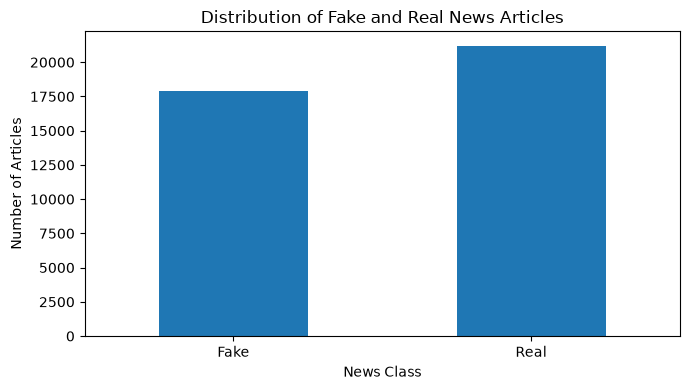

In [50]:
# Counter is used to count frequently occurring words.
from collections import Counter

# Count the number of articles in each class.
class_counts = df["label"].value_counts().sort_index()

# Map numerical labels to readable class names for the plot.
class_counts.index = ["Fake", "Real"]

# Plot the number of fake and real articles.
class_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Distribution of Fake and Real News Articles")
plt.xlabel("News Class")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

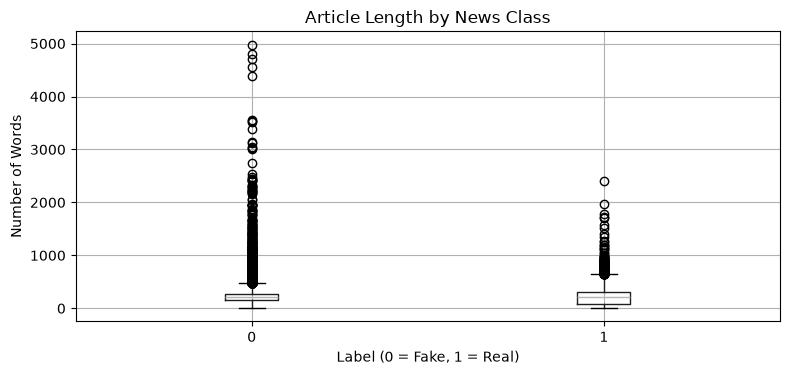

In [51]:
# Calculate the number of words in each cleaned article.
# Article length helps us understand variation in text size.
df["text_word_count"] = df["text"].str.split().str.len()

# Compare article lengths for Fake and Real news.
df.boxplot(column="text_word_count", by="label", figsize=(8, 4))

plt.title("Article Length by News Class")
plt.suptitle("")
plt.xlabel("Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

In [52]:
# Combine the cleaned article text separately for each class.
fake_text = " ".join(df.loc[df["label"] == 0, "text"])
real_text = " ".join(df.loc[df["label"] == 1, "text"])

# Count the occurrences of each word in Fake and Real articles.
fake_word_counts = Counter(fake_text.split())
real_word_counts = Counter(real_text.split())

# Select the 15 most frequent words from each class.
top_fake_words = fake_word_counts.most_common(15)
top_real_words = real_word_counts.most_common(15)

# Display the frequent words for inspection.
print("Top words in Fake news:")
print(top_fake_words)

print("\nTop words in Real news:")
print(top_real_words)

Top words in Fake news:
[('trump', 68083), ('not', 35131), ('said', 24814), ('people', 21200), ('president', 20795), ('one', 18856), ('would', 18265), ('donald', 15285), ('no', 14403), ('like', 14371), ('clinton', 13527), ('obama', 13381), ('also', 11399), ('even', 11321), ('via', 11056)]

Top words in Real news:
[('said', 97831), ('trump', 54067), ('u', 44002), ('not', 35731), ('would', 31240), ('reuters', 28647), ('president', 27858), ('state', 20800), ('government', 18550), ('new', 16740), ('house', 16484), ('states', 16416), ('republican', 16140), ('also', 15750), ('united', 15365)]


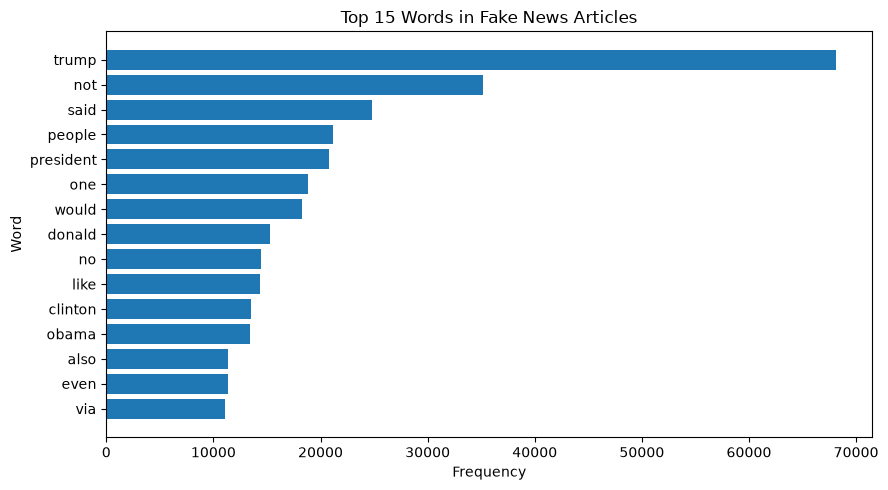

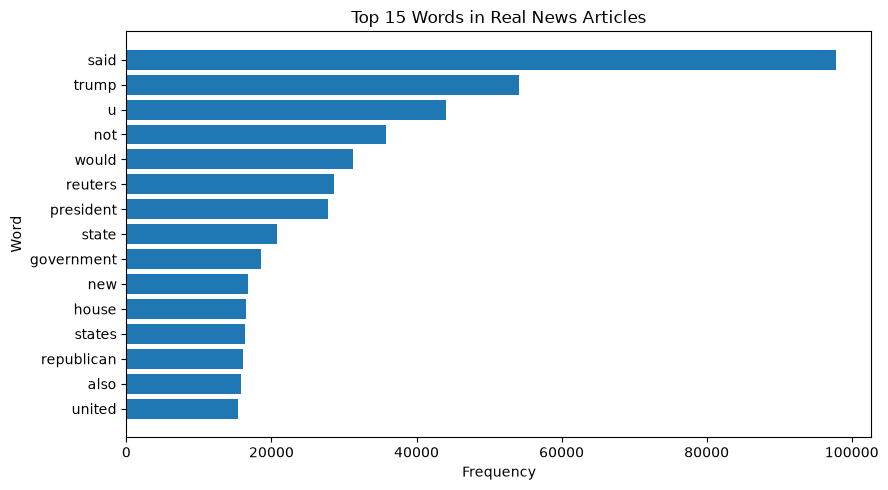

In [53]:
# Extract words and counts for the Fake news plot.
fake_words, fake_counts = zip(*top_fake_words)

# Plot the 15 most frequent words in Fake news articles.
plt.figure(figsize=(9, 5))
plt.barh(fake_words[::-1], fake_counts[::-1])
plt.title("Top 15 Words in Fake News Articles")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

# Extract words and counts for the Real news plot.
real_words, real_counts = zip(*top_real_words)

# Plot the 15 most frequent words in Real news articles.
plt.figure(figsize=(9, 5))
plt.barh(real_words[::-1], real_counts[::-1])
plt.title("Top 15 Words in Real News Articles")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

In [54]:
# Combine the cleaned article text separately for each class.
fake_text = " ".join(df.loc[df["label"] == 0, "text"])
real_text = " ".join(df.loc[df["label"] == 1, "text"])

# Count the occurrences of each word in Fake and Real articles.
fake_word_counts = Counter(fake_text.split())
real_word_counts = Counter(real_text.split())

# Select the 15 most frequent words from each class.
top_fake_words = fake_word_counts.most_common(15)
top_real_words = real_word_counts.most_common(15)

# Display the frequent words for inspection.
print("Top words in Fake news:")
print(top_fake_words)

print("\nTop words in Real news:")
print(top_real_words)

Top words in Fake news:
[('trump', 68083), ('not', 35131), ('said', 24814), ('people', 21200), ('president', 20795), ('one', 18856), ('would', 18265), ('donald', 15285), ('no', 14403), ('like', 14371), ('clinton', 13527), ('obama', 13381), ('also', 11399), ('even', 11321), ('via', 11056)]

Top words in Real news:
[('said', 97831), ('trump', 54067), ('u', 44002), ('not', 35731), ('would', 31240), ('reuters', 28647), ('president', 27858), ('state', 20800), ('government', 18550), ('new', 16740), ('house', 16484), ('states', 16416), ('republican', 16140), ('also', 15750), ('united', 15365)]


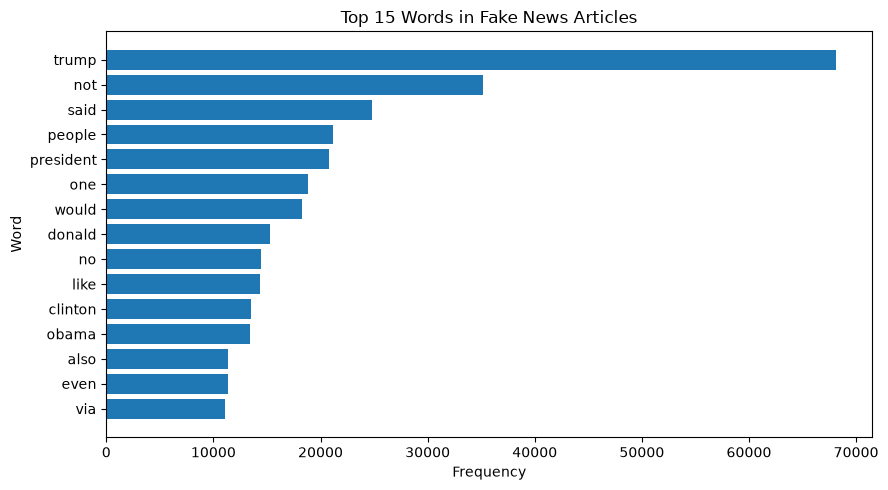

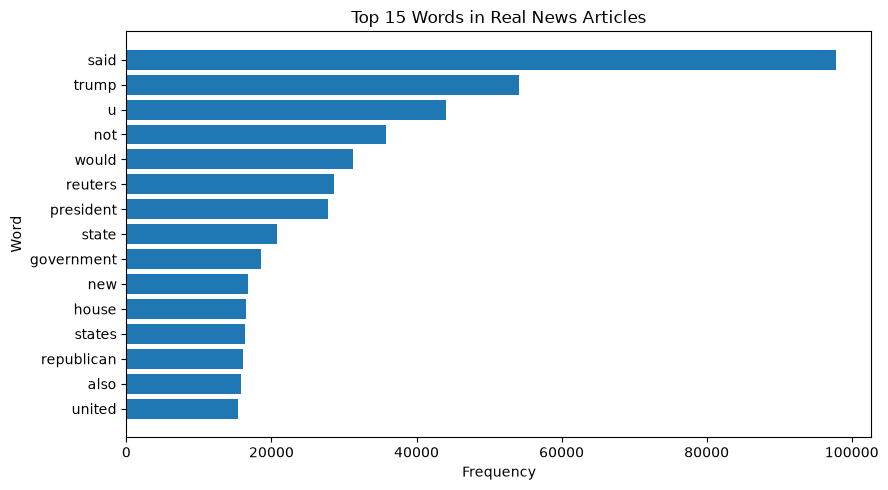

In [55]:
# Extract words and counts for the Fake news plot.
fake_words, fake_counts = zip(*top_fake_words)

# Plot the 15 most frequent words in Fake news articles.
plt.figure(figsize=(9, 5))
plt.barh(fake_words[::-1], fake_counts[::-1])
plt.title("Top 15 Words in Fake News Articles")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

# Extract words and counts for the Real news plot.
real_words, real_counts = zip(*top_real_words)

# Plot the 15 most frequent words in Real news articles.
plt.figure(figsize=(9, 5))
plt.barh(real_words[::-1], real_counts[::-1])
plt.title("Top 15 Words in Real News Articles")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

In [56]:
# train_test_split divides the dataset into training and testing sets.
from sklearn.model_selection import train_test_split

# TfidfVectorizer converts text into numerical TF-IDF features.
from sklearn.feature_extraction.text import TfidfVectorizer

In [57]:
# Combine the cleaned title and article body because both may contain
# useful information for distinguishing fake news from real news.
X = (df["title"] + " " + df["text"]).str.strip()

# Extract the target labels: 0 = Fake news, 1 = Real news.
y = df["label"]

# Verify the number of input samples and target labels.
print("Input samples:", len(X))
print("Target labels:", len(y))
print("Missing input values:", X.isna().sum())
print("Missing target values:", y.isna().sum())

Input samples: 39105
Target labels: 39105
Missing input values: 0
Missing target values: 0


In [58]:
# Reserve 20% of the data for testing and use 80% for training.
# Stratification preserves the approximate Fake/Real class proportions.
# random_state ensures that the split is reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the training and testing sets.
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Verify the class distribution in both sets.
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 31284
Testing samples: 7821

Training class distribution:
label
0    14326
1    16958
Name: count, dtype: int64

Testing class distribution:
label
0    3582
1    4239
Name: count, dtype: int64


In [59]:
# Limit the vocabulary to the 50,000 most useful terms to control memory use.
# Unigrams and bigrams capture individual words and two-word expressions.
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Learn the vocabulary and IDF weights from training text only.
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test text using the already learned vocabulary and weights.
# Do not fit the vectorizer on test data.
X_test_tfidf = tfidf.transform(X_test)

# Display the dimensions of the resulting sparse feature matrices.
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (31284, 50000)
Testing TF-IDF shape: (7821, 50000)
Vocabulary size: 50000


In [60]:
# Confirm that the feature matrices contain no invalid numerical values.
print("Training matrix contains only finite values:",
      __import__("numpy").isfinite(X_train_tfidf.data).all())

print("Testing matrix contains only finite values:",
      __import__("numpy").isfinite(X_test_tfidf.data).all())

# Display a few feature names to understand the learned vocabulary.
print("\nSample TF-IDF features:")
print(tfidf.get_feature_names_out()[:20])

Training matrix contains only finite values: True
Testing matrix contains only finite values: True

Sample TF-IDF features:
['aa' 'aadhaar' 'aapl' 'aaron' 'aaron bernstein' 'aba' 'ababa' 'aback'
 'abadi' 'abadi said' 'abandon' 'abandon nuclear' 'abandoned' 'abandoning'
 'abbas' 'abbasi' 'abbott' 'abbott said' 'abby' 'abc']



### Model Building and Hyperparameter Tuning

In this phase, we will train and optimize two Machine Learning classifiers to distinguish Fake and Real news articles.

### Models
1. Logistic Regression: A linear classification algorithm suitable for high-dimensional TF-IDF features.
2. Multinomial Naive Bayes: A probabilistic classifier commonly used for text classification.

### Optimization strategy
- Train baseline models using default settings.
- Use GridSearchCV to find suitable hyperparameters.
- Use stratified 3-fold cross-validation to evaluate parameter combinations.
- Optimize the F1-score because the dataset contains different numbers of Fake and Real articles.
- Compare models using cross-validation results and select the best candidate.

The test set will not be used for hyperparameter tuning. Final evaluation on unseen test data will be performed in Phase 6.


In [ ]:
# Import the classifiers used for Fake/Real news classification.
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Import tools for hyperparameter tuning and stratified cross-validation.
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Import F1-score for comparing baseline model predictions.
from sklearn.metrics import f1_score



In [65]:
# Initialize Logistic Regression with its standard regularization setting.
baseline_lr = LogisticRegression(max_iter=1000, random_state=42)

# Initialize Multinomial Naive Bayes with its default smoothing parameter.
baseline_nb = MultinomialNB()

# Train both baseline models using the training TF-IDF features.
baseline_lr.fit(X_train_tfidf, y_train)
baseline_nb.fit(X_train_tfidf, y_train)

# Calculate training F1-scores to establish baseline performance.
# These are training scores, not estimates of unseen-data performance.
baseline_results = {
    "Logistic Regression": f1_score(
        y_train, baseline_lr.predict(X_train_tfidf)
    ),
    "Multinomial Naive Bayes": f1_score(
        y_train, baseline_nb.predict(X_train_tfidf)
    )
}

# Display baseline training results.
for model_name, score in baseline_results.items():
    print(f"{model_name} training F1-score: {score:.4f}")

Logistic Regression training F1-score: 0.9954
Multinomial Naive Bayes training F1-score: 0.9678


In [66]:
# Use stratified folds to preserve the Fake/Real class proportions.
# Shuffling ensures that the folds are not dependent on row order.
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [67]:
# Test a small, targeted set of regularization strengths and class weights.
# C controls regularization: smaller values apply stronger regularization.
lr_param_grid = {
    "C": [0.5, 1.0, 2.0],
    "class_weight": [None, "balanced"]
}

# Search for the parameter combination with the highest mean CV F1-score.
lr_grid = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ),
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fit the search using training data only.
lr_grid.fit(X_train_tfidf, y_train)

# Display the best hyperparameters and cross-validation score.
print("Best Logistic Regression parameters:")
print(lr_grid.best_params_)

print(f"Best Logistic Regression CV F1-score: {lr_grid.best_score_:.4f}")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Logistic Regression parameters:
{'C': 2.0, 'class_weight': 'balanced'}
Best Logistic Regression CV F1-score: 0.9924


In [68]:
# Alpha controls Laplace/Lidstone smoothing in Multinomial Naive Bayes.
# Testing multiple values helps find suitable smoothing strength.
nb_param_grid = {
    "alpha": [0.1, 0.5, 1.0, 2.0]
}

# Search for the smoothing parameter with the highest mean CV F1-score.
nb_grid = GridSearchCV(
    estimator=MultinomialNB(),
    param_grid=nb_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fit the search using training data only.
nb_grid.fit(X_train_tfidf, y_train)

# Display the best hyperparameters and cross-validation score.
print("Best Multinomial Naive Bayes parameters:")
print(nb_grid.best_params_)

print(f"Best Multinomial Naive Bayes CV F1-score: {nb_grid.best_score_:.4f}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Multinomial Naive Bayes parameters:
{'alpha': 0.1}
Best Multinomial Naive Bayes CV F1-score: 0.9659


In [69]:
# Collect the baseline training scores and tuned cross-validation scores.
# Note that training and cross-validation scores measure different things.
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Baseline)",
        "Multinomial Naive Bayes (Baseline)",
        "Logistic Regression (Tuned)",
        "Multinomial Naive Bayes (Tuned)"
    ],
    "F1-score": [
        baseline_results["Logistic Regression"],
        baseline_results["Multinomial Naive Bayes"],
        lr_grid.best_score_,
        nb_grid.best_score_
    ],
    "Score Type": [
        "Training",
        "Training",
        "3-fold CV",
        "3-fold CV"
    ]
})

# Display results for comparison without treating training and CV scores
# as directly equivalent measurements.
display(model_comparison)

,Model,F1-score,Score Type
0,Logistic Regression (Baseline),0.995412,Training
1,Multinomial Naive Bayes (Baseline),0.967811,Training
2,Logistic Regression (Tuned),0.992441,3-fold CV
3,Multinomial Naive Bayes (Tuned),0.965929,3-fold CV


In [70]:
# Select the tuned model with the highest cross-validation F1-score.
# The held-out test set remains untouched until Phase 6.
if lr_grid.best_score_ >= nb_grid.best_score_:
    best_model = lr_grid.best_estimator_
    best_model_name = "Logistic Regression"
    best_cv_f1 = lr_grid.best_score_
else:
    best_model = nb_grid.best_estimator_
    best_model_name = "Multinomial Naive Bayes"
    best_cv_f1 = nb_grid.best_score_

print("Selected candidate model:", best_model_name)
print(f"Best cross-validation F1-score: {best_cv_f1:.4f}")

Selected candidate model: Logistic Regression
Best cross-validation F1-score: 0.9924


In [72]:
# Model Evaluation


# Import the evaluation metrics required to measure model performance.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict the labels of the unseen test articles using the selected model.
y_test_pred = best_model.predict(X_test_tfidf)

# Calculate the probability of an article belonging to the Real class.
# This is required for ROC-AUC evaluation.
y_test_prob = best_model.predict_proba(X_test_tfidf)[:, 1]

# Calculate the evaluation metrics.
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, pos_label=1)
test_recall = recall_score(y_test, y_test_pred, pos_label=1)
test_f1 = f1_score(y_test, y_test_pred, pos_label=1)
test_roc_auc = roc_auc_score(y_test, y_test_prob)

# Display the final test-set performance.
print(f"Selected Model : {best_model_name}")
print(f"Accuracy       : {test_accuracy:.4f}")
print(f"Precision      : {test_precision:.4f}")
print(f"Recall         : {test_recall:.4f}")
print(f"F1-score       : {test_f1:.4f}")
print(f"ROC-AUC        : {test_roc_auc:.4f}")

Selected Model : Logistic Regression
Accuracy       : 0.9928
Precision      : 0.9902
Recall         : 0.9967
F1-score       : 0.9934
ROC-AUC        : 0.9997


In [73]:
# Display precision, recall, F1-score, and sample count for each class.
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        digits=4,
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

        Fake     0.9961    0.9883    0.9922      3582
        Real     0.9902    0.9967    0.9934      4239

    accuracy                         0.9928      7821
   macro avg     0.9931    0.9925    0.9928      7821
weighted avg     0.9929    0.9928    0.9928      7821



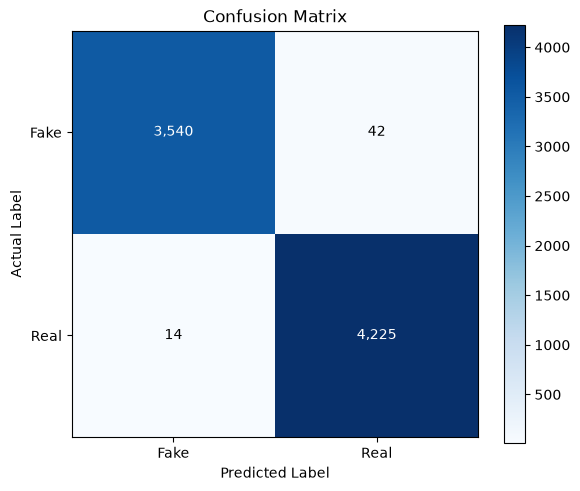

In [74]:
# Import the confusion matrix function.
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Compare actual labels with the model's predictions.
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

# Plot the confusion matrix without requiring an additional visualization library.
fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(image, ax=ax)

# Label the axes using the project's class definitions.
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"],
    xlabel="Predicted Label",
    ylabel="Actual Label",
    title="Confusion Matrix"
)

# Write the count inside each cell for easier interpretation.
threshold = cm.max() / 2 if cm.max() > 0 else 0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

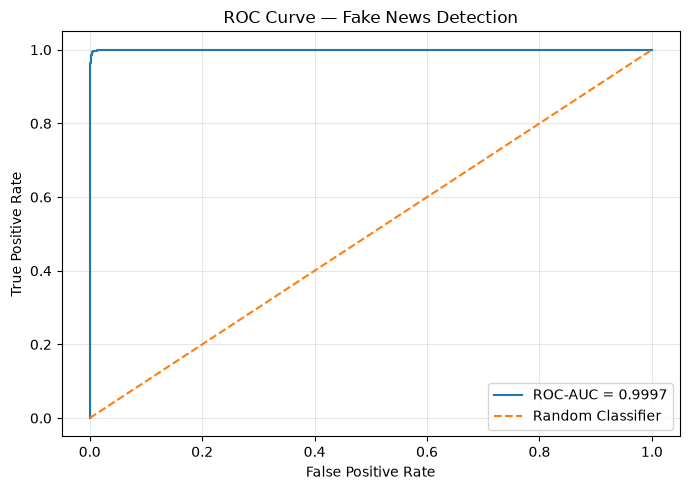

In [75]:
# Import the functions needed to calculate and plot the ROC curve.
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate false-positive and true-positive rates at different thresholds.
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

# Calculate the area under the ROC curve.
roc_auc = roc_auc_score(y_test, y_test_prob)

# Plot the ROC curve.
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Fake News Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [76]:
# Import joblib to save the trained model and vectorizer.
import joblib
from pathlib import Path

# Create a folder to store the artifacts required by the application.
Path("model_artifacts").mkdir(exist_ok=True)

# Save the selected, already-trained model.
joblib.dump(best_model, "model_artifacts/fake_news_model.pkl")

# Save the TF-IDF vectorizer fitted during Phase 4.
joblib.dump(tfidf, "model_artifacts/tfidf_vectorizer.pkl")

# Confirm that both artifacts have been saved.
print("Model saved successfully.")
print("TF-IDF vectorizer saved successfully.")

Model saved successfully.
TF-IDF vectorizer saved successfully.
